# BERT Variant Comparison for Cross-Lingual Classification (XNLI)

**Group:** 90  
**Dataset:** Hugging Face XNLI (`xnli`)  
**Models:** `bert-base-multilingual-cased` (mBERT) and `xlm-roberta-base` (XLM-R)

**Group members**
- 2025AG05424 — Shreeja Mahapatra
- 2025AG05393 — Hari Krishna Moorthy T
- 2025AG05390 — Naveen Ranjolkar

## Objective
Fine-tune both multilingual Transformer models using English XNLI training examples, then compare their zero-shot cross-lingual transfer performance on the XNLI test sets in multiple languages. The task is three-class Natural Language Inference (NLI): entailment, neutral, and contradiction.

> Run the notebook from top to bottom in an environment with internet access. A GPU is strongly recommended. The training and evaluation cells download pretrained checkpoints and XNLI data, fine-tune both models, and save real results. No performance values are fabricated in this notebook.

## 1. Install dependencies

If packages are not installed, run the following command in a terminal or uncomment the cell below. Restart the kernel if required.

In [1]:
# Uncomment if needed:
%pip install -U datasets transformers accelerate evaluate scikit-learn pandas matplotlib seaborn torch sentencepiece tqdm




[notice] A new release of pip is available: 26.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## 2. Imports and reproducibility

In [2]:
import os
import random
import json
import time
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    TrainingArguments,
    Trainer,
    set_seed,
)
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix
)
from IPython.display import display

SEED = 42
set_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

OUTPUT_DIR = "model_outputs"
RESULTS_DIR = "results"
os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

LABEL_NAMES = ["entailment", "neutral", "contradiction"]
ID2LABEL = {i: name for i, name in enumerate(LABEL_NAMES)}
LABEL2ID = {name: i for i, name in ID2LABEL.items()}

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
print("Seed:", SEED)
print("Labels:", ID2LABEL)
# Handle Trainer tokenizer parameter name across Transformers v4 and v5
import inspect
TRAINER_TOKENIZER_KW = "processing_class" if "processing_class" in inspect.signature(Trainer.__init__).parameters else "tokenizer"


/Users/harikrishnamoorthyt/github/ml/bits-assignment/Group90_xnli/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1115 14:28:19.015000 43037 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


PyTorch: 2.14.1
CUDA available: False
Seed: 42
Labels: {0: 'entailment', 1: 'neutral', 2: 'contradiction'}


## 3. Load the XNLI dataset

The `all_languages` configuration contains English training data and multilingual validation/test data. The training set is filtered to English so the experiment measures cross-lingual transfer rather than multilingual supervised training.

The notebook uses the complete English training split by default. For a quick trial on limited hardware, set `MAX_TRAIN_SAMPLES` to a smaller number (for example, 10000). Keep the same setting for both models.

In [3]:
# Load dataset from local storage, or download automatically if missing
from download_dataset import download_xnli_if_needed, DEFAULT_OUTPUT_DIR

raw = download_xnli_if_needed(output_dir="data/xnli")

print("Dataset structure:")
print(raw)
print("\nAvailable splits:", list(raw.keys()))
print("Training columns:", raw["train"].column_names)
print("Example training sample:", raw["train"][0])


[INFO] Authenticated with Hugging Face token.
XNLI Dataset Downloader
Target directory: data/xnli
Languages: ['ar', 'bg', 'de', 'el', 'en', 'es', 'fr', 'hi', 'ru', 'sw', 'th', 'tr', 'ur', 'vi', 'zh']

[Step 1/3] Downloading English training and validation splits...


Generating train split: 392702 examples [00:00, 4232392.10 examples/s]
Generating train split: 2490 examples [00:00, 1100275.70 examples/s]
Tagging English validation: 100%|██████████| 2490/2490 [00:00<00:00, 962120.40 examples/s]



[Step 2/3] Downloading test splits for 15 languages: ar, bg, de, el, en, es, fr, hi, ru, sw, th, tr, ur, vi, zh...
  -> Downloading test split for: ar


Generating train split: 5010 examples [00:00, 1553905.42 examples/s]
Tagging test (ar): 100%|██████████| 5010/5010 [00:00<00:00, 753846.21 examples/s]


  -> Downloading test split for: bg


Generating train split: 5010 examples [00:00, 1061929.61 examples/s]
Tagging test (bg): 100%|██████████| 5010/5010 [00:00<00:00, 530321.60 examples/s]


... (25 outputs left out)

Generating train split: 5010 examples [00:00, 2214974.50 examples/s]
Tagging test (zh): 100%|██████████| 5010/5010 [00:00<00:00, 1345722.90 examples/s]



[Step 3/3] Saving final DatasetDict to local disk at: data/xnli


Saving the dataset (1/1 shards): 100%|██████████| 75150/75150 [00:00<00:00, 3244954.97 examples/s]

[SUCCESS] Dataset successfully saved to data/xnli!
Summary:
  - Train examples:      392,702 (English)
  - Validation examples: 2,490 (English)
  - Test examples:       75,150 across 15 languages (5010 per language)
Dataset structure:
DatasetDict({
    train: Dataset({
        features: ['premise', 'hypothesis', 'label', 'language'],
        num_rows: 392702
    })
    validation: Dataset({
        features: ['premise', 'hypothesis', 'label', 'language'],
        num_rows: 2490
    })
    test: Dataset({
        features: ['premise', 'hypothesis', 'label', 'language'],
        num_rows: 75150
    })
})

Available splits: ['train', 'validation', 'test']
Training columns: ['premise', 'hypothesis', 'label', 'language']
Example training sample: {'premise': 'Conceptually cream skimming has two basic dimensions - product and geography .', 'hypothesis': 'Product and geography are what make cream skimming work .', 'label': 1, 'language': 'en'}


## 4. Prepare English training data and multilingual evaluation data

In [ ]:
MAX_TRAIN_SAMPLES = 10000            
MAX_EVAL_SAMPLES_PER_LANGUAGE = 500  

# English training data (already filtered and tagged as en)
train_ds = raw["train"]
if MAX_TRAIN_SAMPLES is not None:
    train_ds = train_ds.shuffle(seed=SEED).select(range(min(MAX_TRAIN_SAMPLES, len(train_ds))))

# Validation is used during fine-tuning; English validation is retained for model selection.
valid_en = raw["validation"]
if MAX_EVAL_SAMPLES_PER_LANGUAGE is not None:
    valid_en = valid_en.select(range(min(MAX_EVAL_SAMPLES_PER_LANGUAGE, len(valid_en))))

test_all = raw["test"]
languages = sorted(set(test_all["language"]))
print("English training examples:", len(train_ds))
print("English validation examples:", len(valid_en))
print("Test languages:", languages)
print("Label distribution (train):")
display(pd.Series(train_ds["label"]).value_counts().sort_index().rename(index=ID2LABEL).to_frame("count"))


English training examples: 10000
English validation examples: 500
Test languages: ['ar', 'bg', 'de', 'el', 'en', 'es', 'fr', 'hi', 'ru', 'sw', 'th', 'tr', 'ur', 'vi', 'zh']
Label distribution (train):


,count
entailment,3333
neutral,3346
contradiction,3321


## 5. Tokenization

XNLI examples contain a premise and a hypothesis. Both are passed to the tokenizer as a sentence pair. The same maximum sequence length and dynamic padding strategy are used for both models.

In [5]:
MODEL_NAMES = {
    "mBERT": "bert-base-multilingual-cased",
    "XLM-R": "xlm-roberta-base",
}
MAX_LENGTH = 128

def tokenize_dataset(dataset, tokenizer):
    def tokenize_batch(batch):
        return tokenizer(
            batch["premise"],
            batch["hypothesis"],
            truncation=True,
            max_length=MAX_LENGTH,
        )
    tokenized = dataset.map(tokenize_batch, batched=True)
    # Trainer expects the class target in a column named labels.
    if "label" in tokenized.column_names:
        tokenized = tokenized.rename_column("label", "labels")
    keep_cols = {"input_ids", "attention_mask", "token_type_ids", "labels"}
    remove_cols = [c for c in tokenized.column_names if c not in keep_cols]
    return tokenized.remove_columns(remove_cols)

print("Tokenization function ready.")

Tokenization function ready.


## 6. Metrics

Accuracy, macro-averaged precision, macro-averaged recall, and macro-averaged F1 are reported. Macro averaging gives equal weight to each of the three NLI classes.

In [6]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    precision, recall, f1, _ = precision_recall_fscore_support(
        labels, predictions, average="macro", zero_division=0
    )
    return {
        "accuracy": accuracy_score(labels, predictions),
        "precision": precision,
        "recall": recall,
        "f1": f1,
    }

print("Metric function ready: accuracy, macro precision, macro recall, macro F1.")

Metric function ready: accuracy, macro precision, macro recall, macro F1.


## 7. Fine-tune and evaluate mBERT and XLM-R

Both models use the same English training and validation examples, epoch count, batch size, learning rate, maximum sequence length, and random seed. Adjust batch size if GPU memory is limited. Mixed precision is enabled only when CUDA is available.

The defaults are a practical starting point, not a guarantee that training will fit every device. If out-of-memory errors occur, reduce `BATCH_SIZE` and/or `MAX_LENGTH`.

In [7]:
EPOCHS = 1
BATCH_SIZE = 16 if (torch.cuda.is_available() or torch.backends.mps.is_available()) else 8
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01

all_train_results = []
language_results = []
trained_models = {}
prediction_records = []
error_records = []

for short_name, checkpoint in MODEL_NAMES.items():
    print("\n" + "=" * 80)
    print("Training:", short_name, checkpoint)
    tokenizer = AutoTokenizer.from_pretrained(checkpoint)
    model = AutoModelForSequenceClassification.from_pretrained(
        checkpoint,
        num_labels=3,
        id2label=ID2LABEL,
        label2id=LABEL2ID,
    )

    train_tok = tokenize_dataset(train_ds, tokenizer)
    valid_tok = tokenize_dataset(valid_en, tokenizer)
    data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

    model_dir = os.path.join(OUTPUT_DIR, short_name)
    training_args = TrainingArguments(
        output_dir=model_dir,
        learning_rate=LEARNING_RATE,
        per_device_train_batch_size=BATCH_SIZE,
        per_device_eval_batch_size=BATCH_SIZE,
        num_train_epochs=EPOCHS,
        weight_decay=WEIGHT_DECAY,
        eval_strategy="epoch",
        save_strategy="epoch",
        load_best_model_at_end=True,
        metric_for_best_model="f1",
        greater_is_better=True,
        logging_steps=100,
        report_to="none",
        seed=SEED,
        fp16=torch.cuda.is_available(),
    )

    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=train_tok,
        eval_dataset=valid_tok,
        **{TRAINER_TOKENIZER_KW: tokenizer},
        data_collator=data_collator,
        compute_metrics=compute_metrics,
    )

    start = time.time()
    train_output = trainer.train()
    training_minutes = (time.time() - start) / 60
    eval_metrics = trainer.evaluate()
    eval_metrics["model"] = short_name
    eval_metrics["training_minutes"] = training_minutes
    all_train_results.append(eval_metrics)

    trainer.save_model(model_dir)
    tokenizer.save_pretrained(model_dir)
    trained_models[short_name] = (model_dir, tokenizer)

    print("Validation metrics:")
    print({k: round(v, 4) for k, v in eval_metrics.items() if isinstance(v, (int, float))})



Training: mBERT bert-base-multilingual-cased


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 7348.65it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from t

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.794769,0.726071,0.706000,0.717928,0.705805,0.705016


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.20it/s]
[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'ber

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.794769,0.726071,1,0.706000,0.717928,0.705805,0.705016


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.03it/s]


... (3 outputs left out)

Writing model shards: 100%|██████████| 1/1 [00:02<00:00,  2.99s/it]
/Users/harikrishnamoorthyt/github/ml/bits-assignment/Group90_xnli/.venv/lib/python3.10/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.853193,0.851335,1,0.650000,0.672844,0.650254,0.645187


Writing model shards: 100%|██████████| 1/1 [00:03<00:00,  3.06s/it]


Validation metrics:
{'eval_loss': 0.8513, 'eval_accuracy': 0.65, 'eval_precision': 0.6728, 'eval_recall': 0.6503, 'eval_f1': 0.6452, 'training_minutes': 138.7197}


## 8. Cross-lingual test evaluation

Each fine-tuned English model is evaluated independently on every language available in the XNLI test split. These are held-out language test results and are the central evidence for cross-lingual transfer.

For a faster pilot, set `MAX_EVAL_SAMPLES_PER_LANGUAGE` above. For the final submission, preferably use the complete test split.

In [8]:
for short_name, (model_dir, tokenizer) in trained_models.items():
    print("\nEvaluating", short_name)
    model = AutoModelForSequenceClassification.from_pretrained(model_dir)
    model.to("cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu"))
    model.eval()

    for lang in languages:
        if "language" in test_all.column_names:
            lang_ds = test_all.filter(lambda x: x["language"] == lang)
        else:
            lang_ds = test_all

        if MAX_EVAL_SAMPLES_PER_LANGUAGE is not None:
            lang_ds = lang_ds.select(range(min(MAX_EVAL_SAMPLES_PER_LANGUAGE, len(lang_ds))))

        lang_tok = tokenize_dataset(lang_ds, tokenizer)
        trainer = Trainer(
            model=model,
            args=TrainingArguments(
                output_dir=os.path.join(OUTPUT_DIR, "eval_tmp"),
                per_device_eval_batch_size=BATCH_SIZE,
                report_to="none",
            ),
            data_collator=DataCollatorWithPadding(tokenizer=tokenizer),
            compute_metrics=compute_metrics,
            **{TRAINER_TOKENIZER_KW: tokenizer},
        )
        metrics = trainer.evaluate(lang_tok)
        language_results.append({
            "model": short_name,
            "language": lang,
            "n_examples": len(lang_ds),
            "accuracy": metrics["eval_accuracy"],
            "precision_macro": metrics["eval_precision"],
            "recall_macro": metrics["eval_recall"],
            "f1_macro": metrics["eval_f1"],
        })

        pred_output = trainer.predict(lang_tok)
        y_pred = np.argmax(pred_output.predictions, axis=-1)
        y_true = np.array(lang_tok["labels"])
        for i, (gold, pred) in enumerate(zip(y_true, y_pred)):
            if gold != pred:
                error_records.append({
                    "model": short_name,
                    "language": lang,
                    "premise": lang_ds[i]["premise"],
                    "hypothesis": lang_ds[i]["hypothesis"],
                    "true_label": ID2LABEL[int(gold)],
                    "predicted_label": ID2LABEL[int(pred)],
                })

    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

train_results_df = pd.DataFrame(all_train_results)
language_results_df = pd.DataFrame(language_results)
display(train_results_df)
display(language_results_df.head(20))



Evaluating mBERT


Map: 100%|██████████| 500/500 [00:00<00:00, 7115.31 examples/s]
/Users/harikrishnamoorthyt/github/ml/bits-assignment/Group90_xnli/.venv/lib/python3.10/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Step,Accuracy,Precision,Recall,F1
No log,0.927451,0,0.606000,0.656654,0.605608,0.600096


/Users/harikrishnamoorthyt/github/ml/bits-assignment/Group90_xnli/.venv/lib/python3.10/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Map: 100%|██████████| 500/500 [00:00<00:00, 9777.84 examples/s]
/Users/harikrishnamoorthyt/github/ml/bits-assignment/Group90_xnli/.venv/lib/python3.10/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Step,Accuracy,Precision,Recall,F1
No log,0.897777,0,0.610000,0.631205,0.609829,0.611140


... (84 outputs left out)

Training Loss,Validation Loss,Step,Accuracy,Precision,Recall,F1
No log,0.998052,0,0.552000,0.613923,0.551247,0.510051


/Users/harikrishnamoorthyt/github/ml/bits-assignment/Group90_xnli/.venv/lib/python3.10/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


,eval_loss,eval_accuracy,eval_precision,eval_recall,eval_f1,model,training_minutes
0,0.726071,0.706,0.717928,0.705805,0.705016,mBERT,10.022254
1,0.851335,0.650,0.672844,0.650254,0.645187,XLM-R,138.719718


,model,language,n_examples,accuracy,precision_macro,recall_macro,f1_macro
0,mBERT,ar,500,0.606,0.656654,0.605608,0.600096
1,mBERT,bg,500,0.610,0.631205,0.609829,0.611140
2,mBERT,de,500,0.620,0.635711,0.619773,0.614523
3,mBERT,el,500,0.586,0.636612,0.585708,0.584079
4,mBERT,en,500,0.696,0.724473,0.695885,0.695867
5,mBERT,es,500,0.644,0.667947,0.643725,0.641647
6,mBERT,fr,500,0.624,0.642274,0.623789,0.620878
7,mBERT,hi,500,0.532,0.604678,0.531467,0.514130
8,mBERT,ru,500,0.642,0.665303,0.641717,0.639470
9,mBERT,sw,500,0.486,0.525856,0.485824,0.488176


## 9. Compare model performance

,model,mean_accuracy,mean_precision_macro,mean_recall_macro,mean_f1_macro
0,XLM-R,0.561467,0.630576,0.560806,0.530819
1,mBERT,0.591067,0.630959,0.590753,0.584574


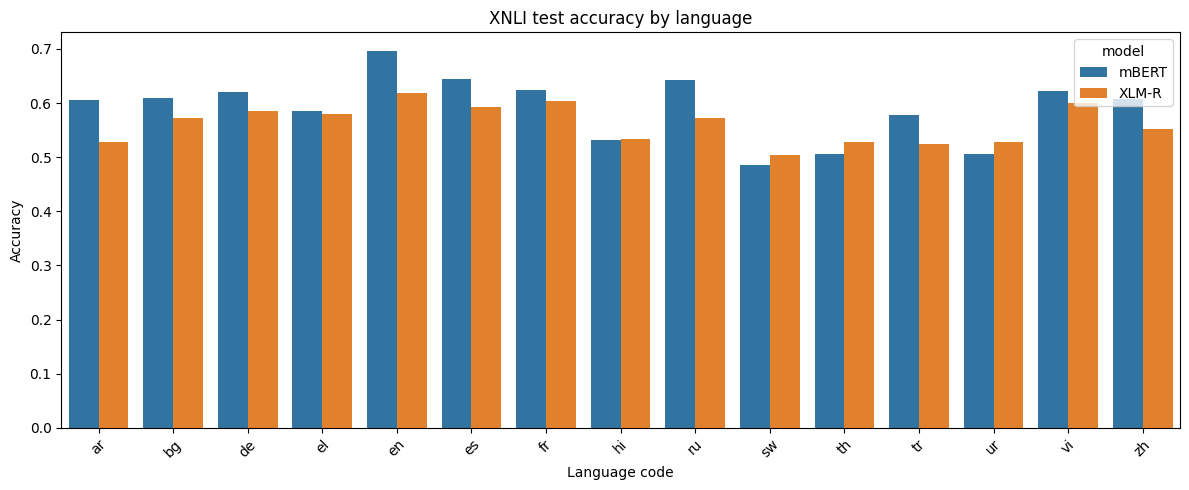

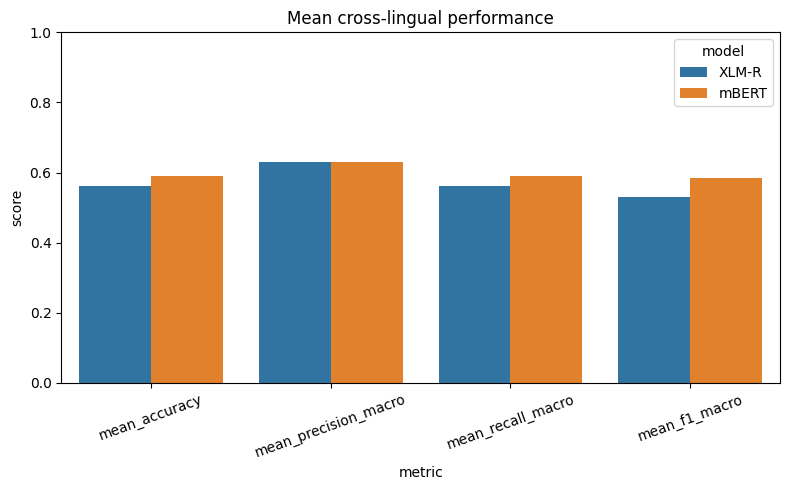

In [9]:
language_results_df.to_csv(os.path.join(RESULTS_DIR, "language_wise_results.csv"), index=False)
train_results_df.to_csv(os.path.join(RESULTS_DIR, "english_validation_results.csv"), index=False)

comparison = (
    language_results_df.groupby("model")[["accuracy", "precision_macro", "recall_macro", "f1_macro"]]
    .mean()
    .reset_index()
    .rename(columns={
        "accuracy": "mean_accuracy",
        "precision_macro": "mean_precision_macro",
        "recall_macro": "mean_recall_macro",
        "f1_macro": "mean_f1_macro",
    })
)
display(comparison)
comparison.to_csv(os.path.join(RESULTS_DIR, "model_comparison.csv"), index=False)

plt.figure(figsize=(12, 5))
sns.barplot(data=language_results_df, x="language", y="accuracy", hue="model")
plt.title("XNLI test accuracy by language")
plt.ylabel("Accuracy")
plt.xlabel("Language code")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "language_accuracy.png"), dpi=160)
plt.show()

plt.figure(figsize=(8, 5))
sns.barplot(data=comparison.melt(id_vars="model", var_name="metric", value_name="score"),
            x="metric", y="score", hue="model")
plt.title("Mean cross-lingual performance")
plt.xticks(rotation=20)
plt.ylim(0, 1)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "overall_model_comparison.png"), dpi=160)
plt.show()

## 10. Predictions on at least five custom examples

These examples are illustrative sentence pairs in English and other languages. The model returns one of entailment, neutral, or contradiction. Custom examples do not have gold labels here, so they demonstrate inference rather than contribute to the reported test metrics.

In [10]:
custom_examples = [
    {"language": "English", "premise": "A woman is slicing vegetables in the kitchen.", "hypothesis": "A person is preparing food."},
    {"language": "English", "premise": "Two children are playing football in a park.", "hypothesis": "The children are sleeping indoors."},
    {"language": "English", "premise": "The train arrived at the station ten minutes late.", "hypothesis": "The train was delayed."},
    {"language": "French", "premise": "Un homme lit un journal dans le train.", "hypothesis": "Une personne est en train de lire."},
    {"language": "Spanish", "premise": "Los estudiantes están sentados en un aula.", "hypothesis": "Los estudiantes están en una clase."},
    {"language": "Hindi", "premise": "बच्चे बगीचे में खेल रहे हैं।", "hypothesis": "कुछ बच्चे बाहर खेल रहे हैं।"},
]

custom_predictions = []
for short_name, (model_dir, tokenizer) in trained_models.items():
    model = AutoModelForSequenceClassification.from_pretrained(model_dir)
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model.to(device)
    model.eval()

    for ex in custom_examples:
        inputs = tokenizer(
            ex["premise"], ex["hypothesis"],
            return_tensors="pt", truncation=True, max_length=MAX_LENGTH
        ).to(device)
        with torch.no_grad():
            logits = model(**inputs).logits
            probs = torch.softmax(logits, dim=-1)[0].cpu().numpy()
        pred_id = int(np.argmax(probs))
        custom_predictions.append({
            "model": short_name,
            "language": ex["language"],
            "premise": ex["premise"],
            "hypothesis": ex["hypothesis"],
            "predicted_label": ID2LABEL[pred_id],
            "confidence": float(probs[pred_id]),
        })
    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

custom_predictions_df = pd.DataFrame(custom_predictions)
display(custom_predictions_df)
custom_predictions_df.to_csv(os.path.join(RESULTS_DIR, "custom_predictions.csv"), index=False)

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 7559.88it/s]


,model,language,premise,hypothesis,predicted_label,confidence
0,mBERT,English,A woman is slicing vegetables in the kitchen.,A person is preparing food.,entailment,0.766958
1,mBERT,English,Two children are playing football in a park.,The children are sleeping indoors.,neutral,0.522784
2,mBERT,English,The train arrived at the station ten minutes l...,The train was delayed.,contradiction,0.757254
3,mBERT,French,Un homme lit un journal dans le train.,Une personne est en train de lire.,entailment,0.681255
4,mBERT,Spanish,Los estudiantes están sentados en un aula.,Los estudiantes están en una clase.,entailment,0.579925
5,mBERT,Hindi,बच्चे बगीचे में खेल रहे हैं।,कुछ बच्चे बाहर खेल रहे हैं।,contradiction,0.499865
6,XLM-R,English,A woman is slicing vegetables in the kitchen.,A person is preparing food.,neutral,0.612373
7,XLM-R,English,Two children are playing football in a park.,The children are sleeping indoors.,neutral,0.570494
8,XLM-R,English,The train arrived at the station ten minutes l...,The train was delayed.,neutral,0.603524
9,XLM-R,French,Un homme lit un journal dans le train.,Une personne est en train de lire.,neutral,0.497637


## 11. Error analysis

The evaluation loop stores incorrect test predictions. Review examples by language and model, identify recurring phenomena (negation, lexical overlap, named entities, word order, morphology, and translation ambiguity), and avoid treating every error as having the same cause.

In [11]:
errors_df = pd.DataFrame(error_records)
if len(errors_df):
    error_summary = (
        errors_df.groupby(["model", "language"])
        .size().reset_index(name="incorrect_examples")
        .sort_values("incorrect_examples", ascending=False)
    )
    display(error_summary.head(20))
    display(errors_df.head(15))
else:
    error_summary = pd.DataFrame(columns=["model", "language", "incorrect_examples"])
    print("No incorrect predictions were recorded in this run, or the evaluation cell has not been run.")

errors_df.to_csv(os.path.join(RESULTS_DIR, "error_analysis.csv"), index=False)
error_summary.to_csv(os.path.join(RESULTS_DIR, "error_summary.csv"), index=False)

,model,language,incorrect_examples
24,mBERT,sw,257
9,XLM-R,sw,248
25,mBERT,th,247
27,mBERT,ur,247
11,XLM-R,tr,238
12,XLM-R,ur,236
0,XLM-R,ar,236
10,XLM-R,th,236
22,mBERT,hi,234
7,XLM-R,hi,233


,model,language,premise,hypothesis,true_label,predicted_label
0,mBERT,ar,حسنا ، لم أكن أفكر حتى حول ذلك ، لكن كنت محبطا...,لم أتحدث معه مرة أخرى.,contradiction,entailment
1,mBERT,ar,حسنا ، لم أكن أفكر حتى حول ذلك ، لكن كنت محبطا...,دار بيننا حديث رائع.,neutral,entailment
2,mBERT,ar,واعتقدت أن ذلك شرف لي ، ولا يزال ، ولايزال ، ك...,لم أكن على علم بأنني لم أكن الشخص الوحيد الذي ...,neutral,contradiction
3,mBERT,ar,واعتقدت أن ذلك شرف لي ، ولا يزال ، ولايزال ، ك...,كان لدي إنطباع أنني كنت الشخص الوحيد الذي لديه...,entailment,neutral
4,mBERT,ar,واعتقدت أن ذلك شرف لي ، ولا يزال ، ولايزال ، ك...,حصلنا جميعنا على نفس العدد بالضبط بغض النظر عن...,contradiction,neutral
5,mBERT,ar,كان ذلك الشيْ الأساسي الوحيد الذي أردنا أن ننق...,أردنا إنقاذ شيء واحد أكثر من الباقي.,entailment,contradiction
6,mBERT,ar,لذلك أنا فعلا غير متأكد لماذا.,أنا متأكد من سبب ذلك.,contradiction,entailment
7,mBERT,ar,لذلك أنا فعلا غير متأكد لماذا.,لا أعرف لماذا حدث هذا.,entailment,contradiction
8,mBERT,ar,هذه هي فاني فلونو ، هي ترعرعت في أوغستا ، جورج...,كان على فاني فلونو إعادة تعيين جدول الأعمال وه...,contradiction,neutral
9,mBERT,ar,هذه هي فاني فلونو ، هي ترعرعت في أوغستا ، جورج...,تمكنت فاني فلونو من التحدث إلينا اليوم رغم جدو...,neutral,contradiction


## 12. Confusion matrices and classification reports

The following cell produces a confusion matrix and detailed per-class report for each model on the English test set. It can be extended to another language by changing `REPORT_LANGUAGE`.

Map: 100%|██████████| 5010/5010 [00:01<00:00, 3128.85 examples/s]
/Users/harikrishnamoorthyt/github/ml/bits-assignment/Group90_xnli/.venv/lib/python3.10/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)



 mBERT classification report — en
               precision    recall  f1-score   support

   entailment       0.79      0.65      0.71      1670
      neutral       0.60      0.81      0.69      1670
contradiction       0.71      0.58      0.64      1670

     accuracy                           0.68      5010
    macro avg       0.70      0.68      0.68      5010
 weighted avg       0.70      0.68      0.68      5010



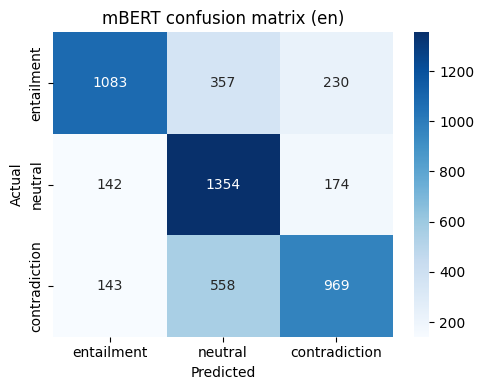

Map: 100%|██████████| 5010/5010 [00:00<00:00, 21208.05 examples/s]
/Users/harikrishnamoorthyt/github/ml/bits-assignment/Group90_xnli/.venv/lib/python3.10/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)



 XLM-R classification report — en
               precision    recall  f1-score   support

   entailment       0.73      0.47      0.57      1670
      neutral       0.52      0.68      0.59      1670
contradiction       0.67      0.69      0.68      1670

     accuracy                           0.61      5010
    macro avg       0.64      0.61      0.61      5010
 weighted avg       0.64      0.61      0.61      5010



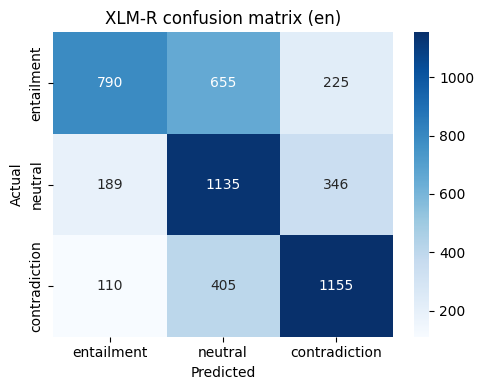

In [12]:
REPORT_LANGUAGE = "en"
report_rows = []

for short_name, (model_dir, tokenizer) in trained_models.items():
    model = AutoModelForSequenceClassification.from_pretrained(model_dir)
    model.to("cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu"))
    model.eval()

    report_ds = test_all.filter(lambda x: x["language"] == REPORT_LANGUAGE) if "language" in test_all.column_names else test_all
    report_tok = tokenize_dataset(report_ds, tokenizer)
    trainer = Trainer(
        model=model,
        args=TrainingArguments(output_dir=os.path.join(OUTPUT_DIR, "report_tmp"),
                               per_device_eval_batch_size=BATCH_SIZE, report_to="none"),
        data_collator=DataCollatorWithPadding(tokenizer=tokenizer),
        **{TRAINER_TOKENIZER_KW: tokenizer},
    )
    output = trainer.predict(report_tok)
    y_true = np.array(report_tok["labels"])
    y_pred = np.argmax(output.predictions, axis=-1)

    print("\n", short_name, "classification report —", REPORT_LANGUAGE)
    print(classification_report(y_true, y_pred, target_names=LABEL_NAMES, zero_division=0))
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=LABEL_NAMES, yticklabels=LABEL_NAMES)
    plt.title(f"{short_name} confusion matrix ({REPORT_LANGUAGE})")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, f"{short_name}_confusion_matrix_{REPORT_LANGUAGE}.png"), dpi=160)
    plt.show()

    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


## 13. Results discussion and conclusion

Complete this section after the notebook has run and the actual metric tables have been generated. Use the observed values rather than assuming XLM-R or mBERT wins.

Discuss:
1. Which model has the higher mean cross-lingual accuracy and macro-F1?
2. Which languages show the largest performance drop relative to English?
3. Is the model ranking consistent across languages?
4. Which NLI class is most frequently confused, based on the classification report/confusion matrix?
5. What error patterns are visible in the sampled incorrect predictions?
6. How might model size, pretraining corpus, tokenization, script coverage, and language similarity explain the results?

**Limitations:** Results depend on the chosen training subset, number of epochs, hardware, random seed, and evaluation languages. Custom examples are qualitative demonstrations and are not a substitute for a held-out benchmark. English-only fine-tuning tests cross-lingual transfer, not fully supervised multilingual classification.

## 14. Save a run summary

This cell records the main experiment settings and the language/model metrics for reproducibility.

In [13]:
run_summary = {
    "group": 90,
    "dataset": "xnli",
    "models": MODEL_NAMES,
    "training_language": "English",
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "max_length": MAX_LENGTH,
    "seed": SEED,
    "train_examples": len(train_ds),
    "validation_examples": len(valid_en),
    "test_languages": languages,
    "device": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU",
}
with open(os.path.join(RESULTS_DIR, "run_summary.json"), "w", encoding="utf-8") as f:
    json.dump(run_summary, f, indent=2, ensure_ascii=False)

print("Saved results to:", os.path.abspath(RESULTS_DIR))
print("Files:", sorted(os.listdir(RESULTS_DIR)))

Saved results to: /Users/harikrishnamoorthyt/github/ml/bits-assignment/Group90_xnli/results
Files: ['README.txt', 'XLM-R_confusion_matrix_en.png', 'custom_predictions.csv', 'english_validation_results.csv', 'error_analysis.csv', 'error_summary.csv', 'language_accuracy.png', 'language_wise_results.csv', 'mBERT_confusion_matrix_en.png', 'model_comparison.csv', 'overall_model_comparison.png', 'run_summary.json']


## References
- Hugging Face Datasets — XNLI: https://huggingface.co/datasets/xnli
- Multilingual BERT checkpoint: https://huggingface.co/bert-base-multilingual-cased
- XLM-RoBERTa checkpoint: https://huggingface.co/xlm-roberta-base
- Conneau et al. (2018), *XNLI: Evaluating Cross-lingual Sentence Representations*.
- Conneau et al. (2020), *Unsupervised Cross-lingual Representation Learning at Scale*.